In [80]:
import sys
import importlib.util
import subprocess

if importlib.util.find_spec("sionna") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "sionna-rt"
    ])
    print("Sionna RT installed.")
else:
    print("Sionna is already installed.")

Sionna is already installed.


# Setup
Scene, antennas, the base station BS1 at (0, 0, 0) and the two receivers RX1 at (r, −5, 5) and RX2 at (2r, −5, 5), with r = 20 m.

In [81]:
# Imported Sionna and the functions we will use
# Imported the NumPy library for mathematical operations
import sionna.rt
import mitsuba as mi
from sionna.rt import (
    PlanarArray,
    Transmitter,
    Receiver,
    load_scene,
    PathSolver,
    SceneObject,
    ITURadioMaterial,
    InteractionType
    )
import numpy as np
import matplotlib.pyplot as plt
# from google.colab import output
# output.enable_custom_widget_manager()

In [82]:
# Called our environment and loaded the scene
scene = load_scene()

In [83]:
# Set our frequency to 7 GHz and the other parameters
scene.frequency = 7e9
tx_power_dbm = 30
c = 299792458.0
r = 20

In [84]:
# Using the PlanarArray function, we defined the number of Tx antenna elements, to be used as our base station, antenna properties and orientation

scene.tx_array= PlanarArray(
    num_rows=1,
    num_cols=1,
    pattern="iso",
    polarization="V",)

In [85]:
# We defined the properties of our receiving antenna
scene.rx_array= PlanarArray(
    num_rows=1,
    num_cols=1,
    pattern="iso",
    polarization="V",
)

In [86]:
# Named our transmitter Base Station 1 and defined its position
bs = Transmitter(
    name="BS1",
    position=[0, 0, 0]
)

In [87]:
# Added our base station to the scene
scene.add(bs)

In [88]:
# Named our first receiver and set its position from the base station
rx1 = Receiver(
    name="RX1",
    position=[r, -5, 5]
)

In [89]:
# Named our second receiver and set its position from the base station
rx2 = Receiver(
    name="RX2",
    position=[2*r, -5, 5]
)

In [90]:
# Added our receivers to the scene
scene.add(rx1)
scene.add(rx2)

In [91]:
# Printed the position of each receiver to make sure their positions were correct
for name in ["RX1", "RX2"]:
    rx = scene.get(name)
    print(name, np.array(rx.position))

RX1 [[20.]
 [-5.]
 [ 5.]]
RX2 [[40.]
 [-5.]
 [ 5.]]


## Free-space reference: RSS and FSPL without the building

In [92]:
# Calculated the wavelength (c and tx_power_dbm are defined in the parameter cell)
# Calculated the free space path loss values for each receiver
# path gain = - path loss
# Calculated the received signal strength (RSS) for each receiver
wavelength = c/ scene.frequency
# Euclidean distance between the base station and each receiver
bs_pos = np.array(bs.position).ravel()
d1 = np.linalg.norm(np.array(rx1.position).ravel() - bs_pos)
d2 = np.linalg.norm(np.array(rx2.position).ravel() - bs_pos)
print(f"Distance BS1-RX1: {d1:.2f} m")
print(f"Distance BS1-RX2: {d2:.2f} m")

fspl1 = 20*np.log10(4*np.pi*d1/wavelength)
fspl2 = 20*np.log10(4*np.pi*d2/wavelength)

rss1 = tx_power_dbm - fspl1
rss2 = tx_power_dbm - fspl2

print(f"RSS at RX1: {rss1} dBm")
print(f"RSS at RX2: {rss2} dBm")

print(f"FSPL at RX1: {fspl1} dB")
print(f"FSPL at RX2: {fspl2} dB")

# Convert received power from dBm to nanowatts for comparing
p_rx1 = 10**((rss1 - 30) / 10) * 1e9
p_rx2 = 10**((rss2 - 30) / 10) * 1e9

print(f"RX1: {p_rx1.item():.2f} nW")
print(f"RX2: {p_rx2.item():.2f} nW")

print(f"RX2 / RX1: {((p_rx2 / p_rx1).item()):.2f}")

Distance BS1-RX1: 21.21 m
Distance BS1-RX2: 40.62 m
RSS at RX1: [-45.881874] dBm
RSS at RX2: [-51.524582] dBm
FSPL at RX1: [75.881874] dB
FSPL at RX2: [81.52458] dB
RX1: 25.81 nW
RX2: 7.04 nW
RX2 / RX1: 0.27


**Explanation:**

| Receiver | Position | Distance to BS1 | FSPL | RSS |
|---|---|---|---|---|
| RX1 | (20, −5, 5) | 21.21 m | 75.88 dB | −45.88 dBm |
| RX2 | (40, −5, 5) | 40.62 m | 81.52 dB | −51.52 dBm |

RSS decreases as the distance increases. The distances are calculated as Euclidean distances from BS1, √(x² + y² + z²). Because both receivers have the same y and z offset, RX2 is not exactly twice as far as RX1 but 1.92 times (40.62 / 21.21). This increases the free-space path loss by 20·log₁₀(1.92) ≈ 5.64 dB, so the RSS drops by 5.64 dB. In linear units the received power falls from 25.81 nW to 7.04 nW, a ratio of 0.27 ≈ (21.21 / 40.62)². This confirms the inverse-square law: the received power is proportional to 1/d². The RSS does not decrease linearly with distance but logarithmically (by 20·log₁₀(d)). The "Without Building" bars in Question 3 show these free-space values.

## Helper functions

`calculate_rss` turns the propagation paths computed by Sionna into path gain and RSS. It is used in every question.

The other functions are used by the additional experiments (Questions 1, 2 and 5–11). Each of these experiments builds its own small scene with the same base station, antennas, frequency and building as above, so the main `scene` is not changed.

In [93]:
# Calculate path gain and RSS from the propagation paths
def calculate_rss(paths, tx_power_dbm):

    # Channel coefficient of every path, including the phase shift e^(-j*2*pi*f*tau)
    # caused by its propagation delay tau. (paths.a alone does not contain this phase,
    # so it cannot be used to add the paths with their correct phases.)
    a, tau = paths.cir(out_type="numpy")   # a: [num_rx, num_rx_ant, num_tx, num_tx_ant, num_paths, num_time_steps]

    # Combine propagation paths coherently (amplitude and phase)
    h = np.sum(a, axis=-2)

    # Calculate path gain
    path_gain = np.abs(h)**2
    path_gain_db = 10 * np.log10(path_gain)

    # Calculate received signal strength
    rss_dbm = tx_power_dbm + path_gain_db

    return path_gain_db.reshape(-1), rss_dbm.reshape(-1)


#Helpers for the additional experiments

solver = PathSolver()

# Same solver settings as in Question 3
base_settings = dict(
    max_depth=3,
    los=True,
    specular_reflection=True,
    diffuse_reflection=False,
    diffraction=False,        # set both to True to include diffraction
    edge_diffraction=False,
    refraction=True
)

def make_scene(rx_positions, frequency=7e9):
    """New scene with BS1 at (0, 0, 0), isotropic antennas and one receiver per position."""
    s = load_scene()
    s.frequency = frequency
    s.tx_array = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")
    s.rx_array = PlanarArray(num_rows=1, num_cols=1, pattern="iso", polarization="V")
    s.add(Transmitter(name="BS1", position=[0, 0, 0]))
    for k, pos in enumerate(rx_positions):
        s.add(Receiver(name=f"rx_{k}", position=[float(v) for v in pos]))
    return s

def add_building(s, center=(30, -5, 4), half_size=(5, 5, 7.5), material="concrete", name="building"):
    """Add a box-shaped building. By default it has the same position, size and material as building1."""
    mesh = mi.load_dict({
        "type": "cube",
        "to_world": mi.ScalarTransform4f()
            .translate(list(center))
            .scale(list(half_size))
    })
    s.add(SceneObject(
        mi_mesh=mesh,
        name=name,
        radio_material=ITURadioMaterial(name=f"{name}_{material}", itu_type=material)
    ))

def simulate(s, **changes):
    """Compute the paths with base_settings (single settings can be changed) and return path gain, RSS and paths."""
    settings = dict(base_settings)
    settings.update(changes)
    paths = solver(s, **settings)
    gain, rss = calculate_rss(paths, tx_power_dbm)
    return gain, rss, paths

def single_path_gain(paths, rx_index, kind):
    """Path gain [dB] of one single path at receiver rx_index:
    kind = "los" (direct path) or "reflection" (path with exactly one specular reflection)."""
    valid = np.array(paths.valid)
    a = (np.array(paths.a[0]) + 1j * np.array(paths.a[1])).reshape(valid.shape)
    inter = np.array(paths.interactions)
    for q in range(valid.shape[-1]):
        if not valid[rx_index, 0, q]:
            continue
        first, second = int(inter[0, rx_index, 0, q]), int(inter[1, rx_index, 0, q])
        if kind == "los" and first == int(InteractionType.NONE):
            return 20 * np.log10(np.abs(a[rx_index, 0, q]))
        if kind == "reflection" and first == int(InteractionType.SPECULAR) and second == int(InteractionType.NONE):
            return 20 * np.log10(np.abs(a[rx_index, 0, q]))
    return None

## Question 1: In ideal free space, if the Tx–Rx distance doubles, is the received power halved?

>Write your answers here


In [94]:
# Three receivers in free space (no building) on the x axis at d, 2d and 4d
d_values = [20, 40, 80]
s = make_scene([[d, 0, 0] for d in d_values])
gain, rss, _ = simulate(s)

# Convert RSS from dBm to nanowatts
p_nw = 10**((rss - 30) / 10) * 1e9

for d, r, p in zip(d_values, rss, p_nw):
    print(f"d = {d:2d} m:  RSS = {r:.2f} dBm = {p:.2f} nW")

print()
print(f"P(40 m) / P(20 m) = {p_nw[1] / p_nw[0]:.3f}")
print(f"P(80 m) / P(40 m) = {p_nw[2] / p_nw[1]:.3f}")
print(f"RSS drop when the distance doubles: {rss[0] - rss[1]:.2f} dB")

d = 20 m:  RSS = -45.37 dBm = 29.04 nW
d = 40 m:  RSS = -51.39 dBm = 7.26 nW
d = 80 m:  RSS = -57.41 dBm = 1.81 nW

P(40 m) / P(20 m) = 0.250
P(80 m) / P(40 m) = 0.250
RSS drop when the distance doubles: 6.02 dB


**Explanation:**

| Distance | RSS | Received power |
|---|---|---|
| 20 m | −45.37 dBm | 29.04 nW |
| 40 m | −51.39 dBm | 7.26 nW |
| 80 m | −57.41 dBm | 1.81 nW |

No. In free space the received power is not halved but drops to **one quarter** when the distance doubles: P(40 m) / P(20 m) = 0.250 and P(80 m) / P(40 m) = 0.250. This is the inverse-square law, P ∝ 1/d². The transmitted power spreads over the surface of a sphere (area 4πd²); when d doubles, this area becomes four times larger, so the power per area at the receiver drops to 1/4.

In dB, each doubling of the distance reduces the RSS by 20·log₁₀(2) ≈ 6.02 dB. Halving the power would only be a 3.01 dB drop.

## Question 2: How do the received signal strength (RSS) and the path gain change with distance?

>Write your answers here


**Explanation:**

Both the RSS and the path gain decrease with distance. Since RSS = P_tx + path gain and P_tx = 30 dBm is constant, both change by exactly the same number of dB; the RSS curve is the path gain curve shifted up by 30 dB.

- **Left plot (linear distance axis):** the decrease is not linear. The RSS drops quickly at short distances and more slowly at large distances: from 5 m to 25 m it drops by about 14 dB, from 175 m to 200 m only by about 1 dB.
- **Right plot (logarithmic distance axis):** the path gain is a straight line and matches the formula −FSPL = −20·log₁₀(4πd/λ) exactly. In free space with 0 dBi antennas, path gain = −FSPL.

The numbers show the rule: 10 times the distance (10 m → 100 m) reduces the path gain and the RSS by 20.00 dB (from −69.35 dB to −89.35 dB path gain), and twice the distance reduces them by 6.02 dB (Question 1).

## Question 3: What happens to the RSS and the path gain if an object (building) blocks the direct path?

>Write your answers here


In [95]:
# Create a building geometry using Mitsuba
building_mesh = mi.load_dict({
    "type": "cube",
    "to_world": mi.ScalarTransform4f()
        .translate([30, -5, 4])
        .scale([5, 5, 7.5])
})

print(type(building_mesh))

<class 'mitsuba.Mesh'>


In [96]:
# Create a Sionna scene object from the Mitsuba mesh
building1 = SceneObject(
    mi_mesh=building_mesh,
    name="building1",
    radio_material=ITURadioMaterial(
        name="concrete",
        itu_type="concrete"
    )
)

In [97]:
# Add the building to the scene
scene.add(building1)

In [98]:
solver = PathSolver()

paths_with = solver(
    scene,
    max_depth=3,
    los=True,
    specular_reflection=True,
    diffuse_reflection= False,
    diffraction= False,
    edge_diffraction= False,
    refraction= True
)

In [99]:
scene.preview(paths = paths_with)


In [100]:
scene._preview_widget = None

In [101]:
# List every propagation path with the building present
# and print which interactions (reflection, refraction, ...) it went through
interaction_names = {
    int(InteractionType.SPECULAR): "reflection",
    int(InteractionType.DIFFUSE): "diffuse reflection",
    int(InteractionType.REFRACTION): "refraction",
    int(InteractionType.DIFFRACTION): "diffraction",
}

a_real, a_imag = paths_with.a
valid = np.array(paths_with.valid)              # [num_rx, num_tx, num_paths]
shape = valid.shape
a = (np.array(a_real) + 1j * np.array(a_imag)).reshape(shape)   # amplitude of each path
tau = np.array(paths_with.tau).reshape(shape)                    # delay of each path (s)
inter = np.array(paths_with.interactions)       # [max_depth, num_rx, num_tx, num_paths]
verts = np.array(paths_with.vertices)           # [max_depth, num_rx, num_tx, num_paths, 3]

for i in range(2):
    print(f"RX{i+1}")
    k = 0
    for p in range(valid.shape[-1]):
        if not valid[i, 0, p]:
            continue
        k += 1
        steps = []
        for d in range(inter.shape[0]):
            t = int(inter[d, i, 0, p])
            if t == int(InteractionType.NONE):
                break
            x = verts[d, i, 0, p]
            steps.append(f"{interaction_names.get(t, t)} at x={x[0]:.1f} m, y={x[1]:.1f} m, z={round(float(x[2]), 1) + 0.0:.1f} m")
        if not steps:
            steps = ["line of sight (no interaction)"]
        length = tau[i, 0, p] * c
        power = 20 * np.log10(np.abs(a[i, 0, p]))
        print(f"  Path {k}: length = {length:.2f} m, path gain = {power:.2f} dB")
        for s_ in steps:
            print(f"      -> {s_}")
    print()

RX1
  Path 1: length = 21.21 m, path gain = -75.88 dB
      -> line of sight (no interaction)
  Path 2: length = 30.82 m, path gain = -87.08 dB
      -> reflection at x=25.0 m, y=-4.2 m, z=4.2 m
  Path 3: length = 50.50 m, path gain = -124.62 dB
      -> refraction at x=25.0 m, y=-2.5 m, z=2.5 m
      -> reflection at x=35.0 m, y=-3.5 m, z=3.5 m
      -> refraction at x=25.0 m, y=-4.5 m, z=4.5 m

RX2
  Path 1: length = 44.15 m, path gain = -148.25 dB
      -> refraction at x=25.0 m, y=-3.1 m, z=11.2 m
      -> reflection at x=25.6 m, y=-3.2 m, z=11.5 m
      -> refraction at x=35.0 m, y=-4.4 m, z=7.3 m
  Path 2: length = 40.62 m, path gain = -114.77 dB
      -> refraction at x=25.0 m, y=-3.1 m, z=3.1 m
      -> refraction at x=35.0 m, y=-4.4 m, z=4.4 m
  Path 3: length = 43.01 m, path gain = -118.89 dB
      -> refraction at x=25.0 m, y=-9.4 m, z=3.1 m
      -> reflection at x=26.7 m, y=-10.0 m, z=3.3 m
      -> refraction at x=35.0 m, y=-6.9 m, z=4.4 m



In [102]:
# Remove the building
scene.remove("building1")

# Calculate propagation paths without the building
paths_without = solver(
    scene,
    max_depth=3,
    los=True,
    specular_reflection=True,
    diffuse_reflection=False,
    diffraction=False,
    edge_diffraction= False,
    refraction=True
)

In [103]:
# With building
gain_with, rss_with = calculate_rss(paths_with, tx_power_dbm)

# Without building
gain_without, rss_without = calculate_rss(paths_without, tx_power_dbm)

# Compare results
for i in range(2):
    print(f"RX{i+1}")
    print(f"RSS without building: {rss_without[i]:.2f} dBm")
    print(f"RSS with building:    {rss_with[i]:.2f} dBm")
    print(f"RSS difference:       {rss_with[i] - rss_without[i]:.2f} dB")
    print(f"Path gain without building: {gain_without[i]:.2f} dB")
    print(f"Path gain with building:    {gain_with[i]:.2f} dB")
    print()

RX1
RSS without building: -45.88 dBm
RSS with building:    -44.20 dBm
RSS difference:       1.68 dB
Path gain without building: -75.88 dB
Path gain with building:    -74.20 dB

RX2
RSS without building: -51.52 dBm
RSS with building:    -83.09 dBm
RSS difference:       -31.56 dB
Path gain without building: -81.52 dB
Path gain with building:    -113.09 dB



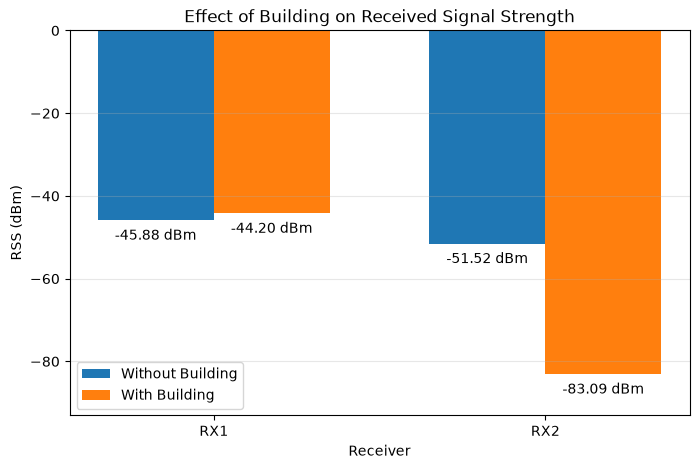

In [104]:
# Grouped bar chart: RSS at each receiver with and without the building
receiver_names = ["RX1", "RX2"]
x = np.arange(len(receiver_names))   # bar group positions
width = 0.35                         # width of each bar

plt.figure(figsize=(8, 5))
bars_without = plt.bar(x - width/2, rss_without, width, label="Without Building")
bars_with = plt.bar(x + width/2, rss_with, width, label="With Building")

# Write the RSS value under each bar
for bar in list(bars_without) + list(bars_with):
    value = bar.get_height()
    plt.annotate(
        f"{value:.2f} dBm",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, -14),
        textcoords="offset points",
        ha="center"
    )

plt.xticks(x, receiver_names)
plt.ylim(min(rss_with) - 10, 0)
plt.xlabel("Receiver")
plt.ylabel("RSS (dBm)")
plt.title("Effect of Building on Received Signal Strength")
plt.legend(loc="lower left")
plt.grid(axis="y", alpha=0.3)
plt.show()

**Explanation:**

| Receiver | RSS without building | RSS with building | Difference | Path gain without | Path gain with |
|---|---|---|---|---|---|
| RX1 (21.21 m, in front of the building) | −45.88 dBm | −44.20 dBm | +1.68 dB | −75.88 dB | −74.20 dB |
| RX2 (40.62 m, behind the building) | −51.52 dBm | −83.08 dBm | −31.56 dB | −81.52 dB | −113.08 dB |

- **RX2 (direct path blocked):** the building blocks the line of sight, so the signal can only reach RX2 through the building (refraction at the front and back walls). The strongest path (Path 2, 40.62 m) has a path gain of −114.77 dB, 33.25 dB below the free-space value. A second path (Path 3, 43.01 m), which is also reflected from the inner side wall of the building, adds to it; the path reflected from the inner surface of the roof (Path 1) is more than 30 dB weaker and has no visible effect. Together, the RSS and the path gain drop by 31.56 dB, which means the received power is about 1400 times smaller. This loss is much larger than the effect of distance (5.64 dB between RX1 and RX2).
- **RX1 (direct path not blocked):** RX1 still receives the direct path. In addition, the wave reflected from the front face of the building (Path 2, 30.82 m, 11.2 dB weaker than the direct path) reaches RX1. At this position, the two waves arrive partly in phase (constructive interference), so the RSS even increases by 1.68 dB. At other positions they can arrive out of phase and the RSS decreases instead (see Questions 6 and 11).

The RSS and the path gain always change by the same number of dB, because RSS = P_tx + path gain.

## Question 4: Does the material of the object change the reflection or the transmission? For this geometry, which of the tested materials gives the strongest reflection?

>Write your answers here



In [105]:
# Transmission: RSS at RX2 (behind the building) for each material

# Remove the concrete building from the scene
if scene.get("building1") is not None:
    scene.remove("building1")

# Materials to compare
materials = ["concrete", "glass", "brick", "wood"]
material_results = {}

for material_name in materials:

    # Create a building with the selected material
    building2 = SceneObject(
        mi_mesh=building_mesh,
        name="building2",
        radio_material=ITURadioMaterial(
            name=f"material_{material_name}",
            itu_type=material_name
        )
    )

    scene.add(building2)

    # Material properties Sionna uses at the current frequency
    # (only correct after the object has been added to the scene)
    eps_r = float(building2.radio_material.relative_permittivity[0])
    sigma = float(building2.radio_material.conductivity[0])

    # Calculate propagation paths
    paths = solver(
        scene,
        max_depth=3,
        los=True,
        specular_reflection=True,
        diffuse_reflection=False,
        diffraction=False,
        edge_diffraction= False
    )

    # Calculate RSS and path gain
    gain, rss = calculate_rss(paths, tx_power_dbm)

    material_results[material_name] = {
        "gain": gain.copy(),
        "rss": rss.copy()
    }

    # Print results
    print(f"\nMaterial: {material_name.upper()}")
    print(f"Relative permittivity: {eps_r:.2f}")
    print(f"Conductivity:          {sigma:.3f} S/m")

    for i in range(2):
        print(f"RX{i+1}")
        print(f"  RSS:       {rss[i]:.2f} dBm")
        print(f"  Path Gain: {gain[i]:.2f} dB")

    # Remove building before testing the next material
    scene.remove("building2")


Material: CONCRETE
Relative permittivity: 5.24
Conductivity:          0.212 S/m
RX1
  RSS:       -44.20 dBm
  Path Gain: -74.20 dB
RX2
  RSS:       -83.09 dBm
  Path Gain: -113.09 dB

Material: GLASS
Relative permittivity: 6.31
Conductivity:          0.049 S/m
RX1
  RSS:       -43.07 dBm
  Path Gain: -73.07 dB
RX2
  RSS:       -61.72 dBm
  Path Gain: -91.72 dB

Material: BRICK
Relative permittivity: 3.91
Conductivity:          0.032 S/m
RX1
  RSS:       -45.86 dBm
  Path Gain: -75.86 dB
RX2
  RSS:       -55.99 dBm
  Path Gain: -85.99 dB

Material: WOOD
Relative permittivity: 1.99
Conductivity:          0.038 S/m
RX1
  RSS:       -44.75 dBm
  Path Gain: -74.75 dB
RX2
  RSS:       -60.19 dBm
  Path Gain: -90.19 dB


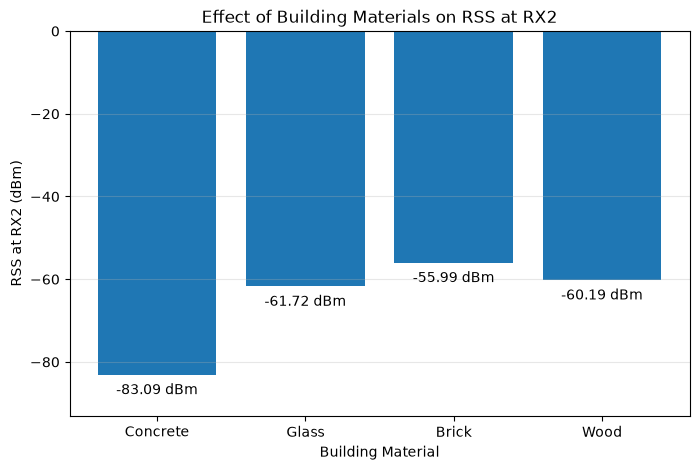

In [106]:
# RSS at RX2 for each building material
material_names = [m.capitalize() for m in material_results]
rss_rx2 = [results["rss"][1] for results in material_results.values()]   # index 1 = RX2

plt.figure(figsize=(8, 5))
bars = plt.bar(material_names, rss_rx2)

# Write the RSS value under each bar
for bar, value in zip(bars, rss_rx2):
    plt.annotate(
        f"{value:.2f} dBm",
        (bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, -14),
        textcoords="offset points",
        ha="center"
    )

plt.ylim(min(rss_rx2) - 10, 0)
plt.xlabel("Building Material")
plt.ylabel("RSS at RX2 (dBm)")
plt.title("Effect of Building Materials on RSS at RX2")
plt.grid(axis="y", alpha=0.3)
plt.show()

Concrete  reflected path gain =  -87.08 dB (-11.20 dB compared to the direct path)
Glass     reflected path gain =  -84.66 dB ( -8.78 dB compared to the direct path)
Brick     reflected path gain =  -89.63 dB (-13.75 dB compared to the direct path)
Wood      reflected path gain =  -91.88 dB (-16.00 dB compared to the direct path)


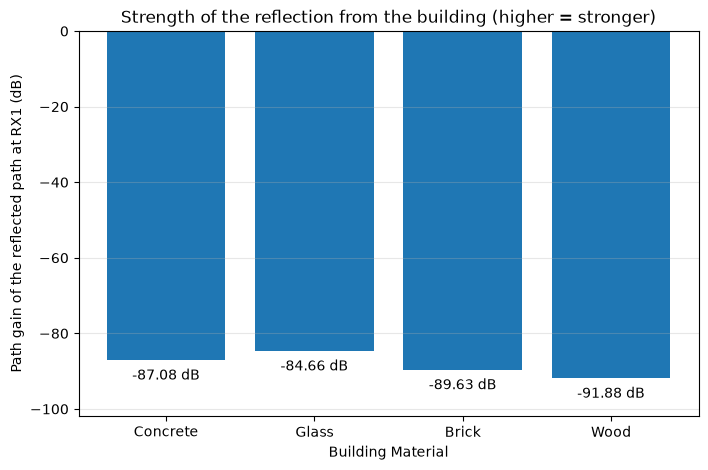

In [107]:
# Reflection: strength of the path reflected from the front face of the building at RX1
# (RX1 is in front of the building and receives the direct path and one reflected path)
reflected_gain = {}
for material_name in materials:
    s = make_scene([[20, -5, 5]])               # RX1 position
    add_building(s, material=material_name)
    gain, rss, paths = simulate(s)
    los = single_path_gain(paths, 0, "los")
    refl = single_path_gain(paths, 0, "reflection")
    reflected_gain[material_name] = refl
    print(f"{material_name.capitalize():9s} reflected path gain = {refl:7.2f} dB "
          f"({refl - los:6.2f} dB compared to the direct path)")

plt.figure(figsize=(8, 5))
names = [m.capitalize() for m in reflected_gain]
values = list(reflected_gain.values())
bars = plt.bar(names, values)
for bar, value in zip(bars, values):
    plt.annotate(f"{value:.2f} dB", (bar.get_x() + bar.get_width() / 2, value),
                 xytext=(0, -14), textcoords="offset points", ha="center")
plt.ylim(min(values) - 10, 0)
plt.xlabel("Building Material")
plt.ylabel("Path gain of the reflected path at RX1 (dB)")
plt.title("Strength of the reflection from the building (higher = stronger)")
plt.grid(axis="y", alpha=0.3)
plt.show()

**Explanation:**

Yes, the material changes both the transmission and the reflection.

**Transmission (signal through the building, RX2):**

| Material | Relative permittivity ε_r / Conductivity σ (at 7 GHz) | RSS at RX2 | Additional loss caused by the building (reference: −51.52 dBm without building) |
|---|---|---|---|
| Concrete | 5.24 / 0.212 S/m | −83.08 dBm | 31.56 dB |
| Glass | 6.31 / 0.049 S/m | −61.72 dBm | 10.20 dB |
| Wood | 1.99 / 0.038 S/m | −60.19 dBm | 8.67 dB |
| Brick | 3.91 / 0.032 S/m | −55.99 dBm | 4.47 dB |

Sionna models each wall as a 0.1 m thick slab. The loss of a wall consists of reflection at its surfaces (increases with ε_r) and absorption inside it (increases with σ). Concrete has by far the highest conductivity and absorbs most of the energy, so it lets the least signal through. Brick has the lowest conductivity and lets the most signal through.

**Reflection (signal reflected from the front face, RX1):**

| Material | Path gain of the reflected path | Compared to the direct path |
|---|---|---|
| Glass | −84.66 dB | −8.78 dB |
| Concrete | −87.08 dB | −11.20 dB |
| Brick | −89.63 dB | −13.75 dB |
| Wood | −91.88 dB | −16.00 dB |

Of the tested materials, **glass gives the strongest reflection**. It has the highest relative permittivity (ε_r = 6.31), i.e. the largest difference to air, so the largest part of the wave is reflected at its surface. Wood (ε_r = 1.99, closest to air) reflects the least.

Reflection and transmission are connected: energy that is reflected cannot pass through the wall. This is one reason why glass, the strongest reflector, lets less signal through than brick and wood. Glass is transparent to visible light, but not to 7 GHz radio waves. The material also changes the RSS at RX1 (between −43.07 and −45.86 dBm), because the strength of the reflected wave changes.

## Question 5: What is the difference between the building being exactly in the middle between Tx and Rx and being shifted (for example along the path or higher up)?

>Write your answers here


In this experiment only RX2 is used: if the building is placed exactly in the middle between BS1 (x = 0) and RX2 (x = 40), its center is at x = 20, where RX1 would be inside the building.

In [108]:
# (a) Building moved along the direct path: center x = 10, 15, 20 (exact middle), 25, 30 (our position)
x_centers = [10, 15, 20, 25, 30]
rss_x = []
for xc in x_centers:
    s = make_scene([[40, -5, 5]])          # only RX2
    add_building(s, center=(xc, -5, 4))
    gain, rss, _ = simulate(s)
    rss_x.append(rss[0])
    note = "  <- exact middle" if xc == 20 else ""
    print(f"Building center x = {xc:2d} m:  RSS at RX2 = {rss[0]:.2f} dBm{note}")

s = make_scene([[40, -5, 5]])
rss_free_rx2 = simulate(s)[1][0]
print(f"No building:              RSS at RX2 = {rss_free_rx2:.2f} dBm")

Building center x = 10 m:  RSS at RX2 = -83.50 dBm
Building center x = 15 m:  RSS at RX2 = -83.50 dBm
Building center x = 20 m:  RSS at RX2 = -84.77 dBm  <- exact middle
Building center x = 25 m:  RSS at RX2 = -83.08 dBm
Building center x = 30 m:  RSS at RX2 = -83.09 dBm
No building:              RSS at RX2 = -51.52 dBm


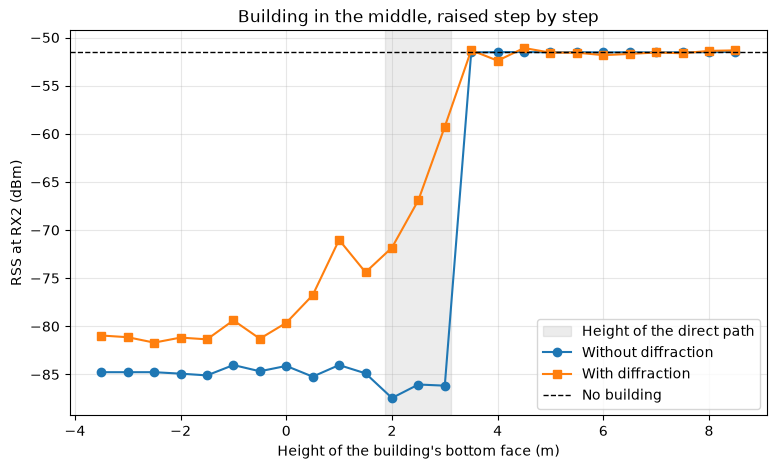

bottom = -3.5 m:  without diffraction  -84.77 dBm,  with diffraction  -80.96 dBm
bottom = -3.0 m:  without diffraction  -84.77 dBm,  with diffraction  -81.13 dBm
bottom = -2.5 m:  without diffraction  -84.77 dBm,  with diffraction  -81.70 dBm
bottom = -2.0 m:  without diffraction  -84.92 dBm,  with diffraction  -81.17 dBm
bottom = -1.5 m:  without diffraction  -85.10 dBm,  with diffraction  -81.36 dBm
bottom = -1.0 m:  without diffraction  -84.03 dBm,  with diffraction  -79.38 dBm
bottom = -0.5 m:  without diffraction  -84.67 dBm,  with diffraction  -81.29 dBm
bottom =  0.0 m:  without diffraction  -84.12 dBm,  with diffraction  -79.64 dBm
bottom =  0.5 m:  without diffraction  -85.23 dBm,  with diffraction  -76.77 dBm
bottom =  1.0 m:  without diffraction  -84.03 dBm,  with diffraction  -71.02 dBm
bottom =  1.5 m:  without diffraction  -84.89 dBm,  with diffraction  -74.39 dBm
bottom =  2.0 m:  without diffraction  -87.45 dBm,  with diffraction  -71.83 dBm
bottom =  2.5 m:  without di

In [109]:
# (b) Building in the middle (x = 20) raised step by step
# The direct path crosses the building region (x = 15...25) at a height of z = 1.9...3.1 m
bottoms, rss_no_diffr, rss_diffr = [], [], []
for zc in np.arange(4, 16.5, 0.5):
    s = make_scene([[40, -5, 5]])
    add_building(s, center=(20, -5, float(zc)))
    bottoms.append(zc - 7.5)                             # height of the building's bottom face
    rss_no_diffr.append(simulate(s)[1][0])
    rss_diffr.append(simulate(s, diffraction=True, edge_diffraction=True)[1][0])

plt.figure(figsize=(9, 5))
plt.axvspan(1.875, 3.125, color="gray", alpha=0.15, label="Height of the direct path")
plt.plot(bottoms, rss_no_diffr, marker="o", label="Without diffraction")
plt.plot(bottoms, rss_diffr, marker="s", label="With diffraction")
plt.axhline(rss_free_rx2, color="black", linestyle="--", linewidth=1, label="No building")
plt.xlabel("Height of the building's bottom face (m)")
plt.ylabel("RSS at RX2 (dBm)")
plt.title("Building in the middle, raised step by step")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

for b, r1, r2 in zip(bottoms, rss_no_diffr, rss_diffr):
    print(f"bottom = {b:4.1f} m:  without diffraction {r1:7.2f} dBm,  with diffraction {r2:7.2f} dBm")

**Explanation:**

**(a) Position along the direct path:** wherever the building is placed between BS1 and RX2 (center at x = 10, 15, 20, 25 or 30 m), the RSS at RX2 stays between −83.08 and −84.77 dBm, compared to −51.52 dBm without the building. The exact middle (x = 20 m, −84.77 dBm) is not special. The loss mainly comes from crossing the two walls, which happens at every position. The small differences (up to 1.7 dB) come from the weaker paths that are reflected inside the building, which depend on the building's position.

**(b) Building raised step by step:** what matters is whether the building covers the direct path, which crosses the building region at a height of 1.9–3.1 m (gray area).
- As long as the bottom face is below the direct path, the RSS stays around −84 to −87 dBm.
- As soon as the bottom face is above the direct path (bottom at 3.5 m), the direct path is free again and the RSS returns to the free-space value (≈ −51.5 dBm).
- **Without diffraction**, this change is a sudden jump of about 35 dB (from −86.17 dBm at 3.0 m to −51.55 dBm at 3.5 m).
- **With diffraction**, the wave also bends around the bottom edge of the building, and the transition becomes gradual: at a bottom height of 2.5 m the RSS is −66.90 dBm instead of −86.05 dBm, and at 3.0 m −59.28 dBm instead of −86.17 dBm. Deep in the shadow (bottom face far below the direct path), diffraction adds only a few dB.

So the position along the path hardly matters; what matters is whether the building blocks the direct path, and how close the direct path is to an edge of the building.

## Question 6: If there is no object between the BS and the Rx, but there is an object behind the Rx, does the RSS at the Rx stay the same?

>Write your answers here


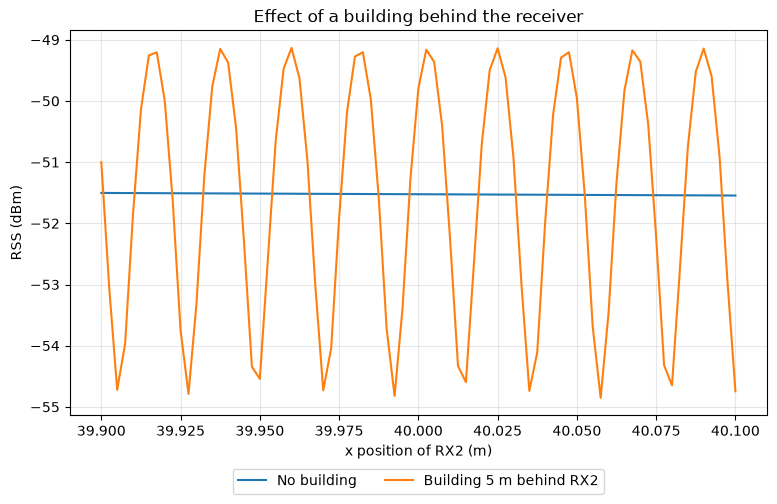

At x = 40.00 m: no building -51.52 dBm, building behind -49.80 dBm (+1.73 dB)
Over the 20 cm range: with the building behind, RSS varies between -54.85 and -49.13 dBm
Without the building it only varies between -51.55 and -51.50 dBm
Reflected path from the building behind: -9.89 dB compared to the direct path


In [110]:
# Building behind RX2: center x = 50, so its front face is at x = 45 (5 m behind RX2)
# Nothing is between BS1 and RX2. RX2 is moved in 0.25 cm steps around x = 40 m.
rx_x = np.round(np.arange(39.90, 40.1001, 0.0025), 4)
positions = [[x, -5, 5] for x in rx_x]

s_free = make_scene(positions)
gain_free, rss_free, _ = simulate(s_free)

s_behind = make_scene(positions)
add_building(s_behind, center=(50, -5, 4))
gain_behind, rss_behind, paths_behind = simulate(s_behind)

plt.figure(figsize=(9, 5))
plt.plot(rx_x, rss_free, label="No building")
plt.plot(rx_x, rss_behind, label="Building 5 m behind RX2")
plt.xlabel("x position of RX2 (m)")
plt.ylabel("RSS (dBm)")
plt.title("Effect of a building behind the receiver")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.grid(True, alpha=0.3)
plt.show()

i40 = int(np.argmin(np.abs(rx_x - 40.0)))
print(f"At x = 40.00 m: no building {rss_free[i40]:.2f} dBm, building behind {rss_behind[i40]:.2f} dBm "
      f"({rss_behind[i40] - rss_free[i40]:+.2f} dB)")
print(f"Over the 20 cm range: with the building behind, RSS varies between {rss_behind.min():.2f} and {rss_behind.max():.2f} dBm")
print(f"Without the building it only varies between {rss_free.min():.2f} and {rss_free.max():.2f} dBm")
refl = single_path_gain(paths_behind, i40, "reflection")
los = single_path_gain(paths_behind, i40, "los")
print(f"Reflected path from the building behind: {refl - los:.2f} dB compared to the direct path")

**Explanation:**

No. Even if nothing is between BS1 and RX2, a building behind RX2 reflects the wave back to the receiver. The reflected wave is 9.89 dB weaker than the direct wave, but it adds to it at the receiver:

- At x = 40.00 m, the RSS increases from −51.52 dBm to −49.80 dBm (+1.73 dB).
- When RX2 is moved by only a few millimetres, the result changes completely: over a 20 cm range, the RSS varies between −54.85 and −49.13 dBm. Without the building, it stays between −51.55 and −51.50 dBm.

The reason is interference. When RX2 moves towards the building by Δx, the direct path gets longer by about Δx and the reflected path gets shorter by about Δx, so their difference changes by about 2·Δx. Every λ/2 = 2.1 cm the two waves switch between arriving in phase (constructive interference, higher RSS) and out of phase (destructive interference, lower RSS). This is why the curve repeats about every 2.1 cm.

## Question 7: Does diffraction occur on a perfectly shaped, smooth object?

>Write your answers here


In [111]:
# Same scene as in Question 3 (concrete building), with and without diffraction
s = make_scene([[20, -5, 5], [40, -5, 5]])
add_building(s)

mat = s.get("building").radio_material
print(f"Scattering coefficient of the building surface: {float(mat.scattering_coefficient[0]):.1f} "
      "(0 = perfectly smooth surface)")
print()

gain_off, rss_off, _ = simulate(s)
gain_on, rss_on, paths_on = simulate(s, diffraction=True, edge_diffraction=True)

# List the diffracted paths
valid = np.array(paths_on.valid)
a = (np.array(paths_on.a[0]) + 1j * np.array(paths_on.a[1])).reshape(valid.shape)
tau = np.array(paths_on.tau).reshape(valid.shape)
inter = np.array(paths_on.interactions)
verts = np.array(paths_on.vertices)
for i in range(2):
    diffracted = [q for q in range(valid.shape[-1])
                  if valid[i, 0, q] and inter[0, i, 0, q] == int(InteractionType.DIFFRACTION) and inter[1, i, 0, q] == int(InteractionType.NONE)]
    print(f"RX{i+1}: {len(diffracted)} paths diffracted once at an edge of the building")
    for q in diffracted:
        v = verts[0, i, 0, q]
        print(f"   edge point x={v[0]:.1f} m, y={v[1]:.1f} m, z={v[2]:.1f} m   "
              f"length = {tau[i, 0, q] * c:.2f} m   path gain = {20 * np.log10(np.abs(a[i, 0, q])):.2f} dB")

print()
for i in range(2):
    print(f"RX{i+1}: RSS without diffraction {rss_off[i]:.2f} dBm, with diffraction {rss_on[i]:.2f} dBm")

Scattering coefficient of the building surface: 0.0 (0 = perfectly smooth surface)

RX1: 4 paths diffracted once at an edge of the building
   edge point x=25.0 m, y=0.0 m, z=3.9 m   length = 32.46 m   path gain = -123.23 dB
   edge point x=25.0 m, y=-3.9 m, z=11.5 m   length = 36.07 m   path gain = -147.32 dB
   edge point x=25.0 m, y=-10.0 m, z=4.0 m   length = 34.36 m   path gain = -126.20 dB
   edge point x=25.0 m, y=-3.6 m, z=-3.5 m   length = 35.46 m   path gain = -139.85 dB
RX2: 0 paths diffracted once at an edge of the building

RX1: RSS without diffraction -44.20 dBm, with diffraction -44.22 dBm
RX2: RSS without diffraction -83.09 dBm, with diffraction -83.84 dBm


**Explanation:**

Yes. The building surface is perfectly smooth (scattering coefficient 0), but 4 diffracted paths still reach RX1, one from each edge of the building's front face (at y = 0 m, y = −10 m, z = 11.5 m and z = −3.5 m).

Diffraction is caused by **edges**, i.e. by sudden changes in the shape of an object, not by the roughness of its surface. A rough surface causes **diffuse reflection (scattering)**, which is a different effect. A perfectly smooth object with sharp edges, like our box-shaped building, therefore still diffracts.

In this geometry the diffracted paths are weak (path gain −123.23 to −147.32 dB, compared to −75.88 dB for the direct path to RX1), so they change the RSS only slightly (RX1: −44.20 → −44.22 dBm, RX2: −83.08 → −83.84 dBm). No path diffracted at a single edge reaches RX2, because behind the 10 m deep building the wave would have to bend around both the front and the back edge. Diffraction becomes important near the edge of a shadow: in Question 5, with the building just above the direct path, diffraction raised the RSS by up to 27 dB (−59.28 instead of −86.17 dBm).

Note: for this box-shaped building, Sionna needs both `diffraction=True` and `edge_diffraction=True` to find the diffracted paths.

## Question 8: If the frequency increases, does the RSS at the Rx increase when there is no object in between?

>Write your answers here


  1.0 GHz (wavelength 29.98 cm):  RSS RX1 = -28.98 dBm,  RSS RX2 = -34.62 dBm
  2.0 GHz (wavelength 14.99 cm):  RSS RX1 = -35.00 dBm,  RSS RX2 = -40.64 dBm
  3.5 GHz (wavelength  8.57 cm):  RSS RX1 = -39.86 dBm,  RSS RX2 = -45.50 dBm
  7.0 GHz (wavelength  4.28 cm):  RSS RX1 = -45.88 dBm,  RSS RX2 = -51.52 dBm
 10.0 GHz (wavelength  3.00 cm):  RSS RX1 = -48.98 dBm,  RSS RX2 = -54.62 dBm
 20.0 GHz (wavelength  1.50 cm):  RSS RX1 = -55.00 dBm,  RSS RX2 = -60.64 dBm
 28.0 GHz (wavelength  1.07 cm):  RSS RX1 = -57.92 dBm,  RSS RX2 = -63.57 dBm
 40.0 GHz (wavelength  0.75 cm):  RSS RX1 = -61.02 dBm,  RSS RX2 = -66.66 dBm


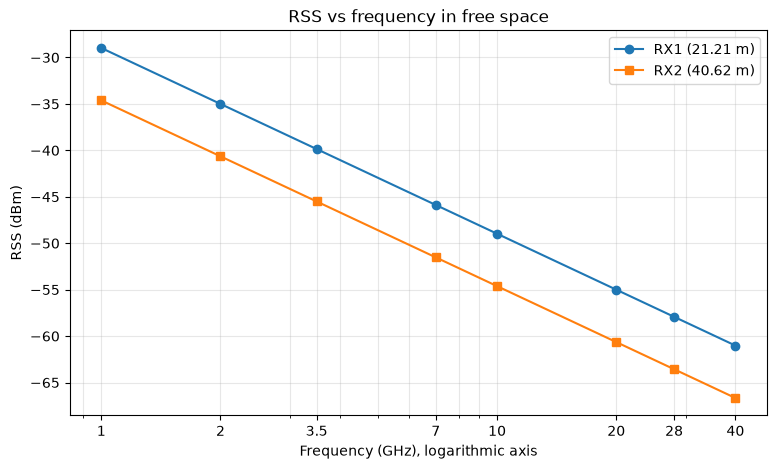


1 GHz -> 10 GHz: RSS at RX1 changes by -20.00 dB
3.5 GHz -> 7 GHz: RSS at RX1 changes by -6.02 dB


In [112]:
# Free space (no building), same receiver positions as RX1 and RX2
frequencies_ghz = [1, 2, 3.5, 7, 10, 20, 28, 40]
rss_f = []
for f in frequencies_ghz:
    s = make_scene([[20, -5, 5], [40, -5, 5]], frequency=f * 1e9)
    gain, rss, _ = simulate(s)
    rss_f.append(rss)
    lam = c / (f * 1e9)
    print(f"{f:5.1f} GHz (wavelength {lam * 100:5.2f} cm):  RSS RX1 = {rss[0]:.2f} dBm,  RSS RX2 = {rss[1]:.2f} dBm")
rss_f = np.array(rss_f)

plt.figure(figsize=(9, 5))
plt.semilogx(frequencies_ghz, rss_f[:, 0], marker="o", label="RX1 (21.21 m)")
plt.semilogx(frequencies_ghz, rss_f[:, 1], marker="s", label="RX2 (40.62 m)")
plt.xticks(frequencies_ghz, [str(f) for f in frequencies_ghz])
plt.xlabel("Frequency (GHz), logarithmic axis")
plt.ylabel("RSS (dBm)")
plt.title("RSS vs frequency in free space")
plt.legend()
plt.grid(True, which="both", alpha=0.3)
plt.show()

print(f"\n1 GHz -> 10 GHz: RSS at RX1 changes by {rss_f[4, 0] - rss_f[0, 0]:.2f} dB")
print(f"3.5 GHz -> 7 GHz: RSS at RX1 changes by {rss_f[3, 0] - rss_f[2, 0]:.2f} dB")

**Explanation:**

No, the RSS decreases when the frequency increases. From 1 GHz to 10 GHz the RSS at RX1 drops by 20.00 dB, and from 3.5 GHz to 7 GHz (doubling the frequency) by 6.02 dB. The free-space path loss is FSPL = 20·log₁₀(4πd/λ) = 20·log₁₀(4πd·f/c), so it increases by 20 dB per 10 times the frequency.

The reason is not that the air absorbs more at higher frequencies (there is no absorption in free space). It is the **effective area (aperture) of the receiving antenna**:

A_e = G·λ² / (4π)

The receiving antenna collects the power that arrives on its effective area. For our isotropic antenna (G = 1), A_e shrinks with λ²: at 3.5 GHz (λ = 8.57 cm) it is 5.84 cm², at 7 GHz (λ = 4.28 cm) only 1.46 cm², i.e. four times smaller, which gives the 6.02 dB drop. With antennas of a fixed physical size (and therefore a higher gain at higher frequencies), this loss could be compensated.

## Question 10: Which kinds of reflecting materials have a stronger effect?

>Write your answers here


In [113]:
# RX1 in front of the building, moved in 0.25 cm steps around x = 20 m
# Metal is added to the four tested materials
rx_x = np.round(np.arange(19.90, 20.1001, 0.0025), 4)
positions = [[x, -5, 5] for x in rx_x]
materials_10 = ["metal", "glass", "concrete", "brick", "wood"]

s = make_scene(positions)
rss_free_10 = simulate(s)[1]

rss_by_material = {}
print("Material   reflected/direct   min RSS     max RSS     variation")
for m in materials_10:
    s = make_scene(positions)
    add_building(s, material=m)
    gain, rss, paths = simulate(s)
    rss_by_material[m] = rss
    i20 = int(np.argmin(np.abs(rx_x - 20.0)))
    ratio = single_path_gain(paths, i20, "reflection") - single_path_gain(paths, i20, "los")
    print(f"{m.capitalize():9s}  {ratio:10.2f} dB   {rss.min():8.2f}   {rss.max():8.2f}   {rss.max() - rss.min():6.2f} dB")
print(f"No building: RSS between {rss_free_10.min():.2f} and {rss_free_10.max():.2f} dBm")


Material   reflected/direct   min RSS     max RSS     variation
Metal           -3.25 dB     -56.18     -41.32    14.86 dB
Glass           -8.78 dB     -50.48     -42.83     7.65 dB
Concrete       -11.20 dB     -48.77     -43.73     5.04 dB
Brick          -13.75 dB     -47.57     -44.36     3.21 dB
Wood           -16.00 dB     -47.75     -44.35     3.41 dB
No building: RSS between -45.92 and -45.84 dBm


**Explanation:**

| Material | Reflected path compared to the direct path | Min RSS | Max RSS | Variation over 20 cm |
|---|---|---|---|---|
| Metal | −3.25 dB | −56.18 dBm | −41.32 dBm | 14.86 dB |
| Glass | −8.78 dB | −50.48 dBm | −42.83 dBm | 7.66 dB |
| Concrete | −11.20 dB | −48.77 dBm | −43.73 dBm | 5.04 dB |
| Brick | −13.75 dB | −47.57 dBm | −44.36 dBm | 3.21 dB |
| Wood | −16.00 dB | −47.75 dBm | −44.35 dBm | 3.41 dB |

Without a building, the RSS stays between −45.92 and −45.84 dBm.

The stronger a material reflects, the stronger its effect on the RSS. In front of the building, the direct and the reflected wave interfere, and the RSS changes between a maximum (in phase) and a minimum (out of phase) every 2.1 cm. The stronger the reflected wave, the deeper these changes:

- **Metal** (very high conductivity) reflects almost all of the energy. The reflected path is only 3.25 dB weaker than the direct path, and this difference is caused only by its longer length (30.82 m vs. 21.21 m: 20·log₁₀(30.82/21.21) = 3.25 dB). The RSS varies by 14.86 dB.
- Among the other materials, a higher relative permittivity gives a stronger reflection: **glass** (ε_r = 6.31, 7.66 dB variation) > **concrete** (ε_r = 5.24, 5.04 dB) > **brick** (ε_r = 3.91) and **wood** (ε_r = 1.99), which both cause only about 3 dB.

So metals and materials with a high relative permittivity have the strongest effect, while materials with a low permittivity, like wood, behave almost like air for the reflection.

## Question 11: Why can two locations at similar distances have different received signal strengths?

>Write your answers here


In [114]:
# (a) Two receivers at exactly the same distance from BS1 (40.62 m):
#     RX2 at (40, -5, 5) behind the building and a second receiver at (40, 5, 5) next to it
s = make_scene([[40, -5, 5], [40, 5, 5]])
add_building(s)
gain, rss, _ = simulate(s)
for pos, r in zip([(40, -5, 5), (40, 5, 5)], rss):
    d = np.linalg.norm(pos)
    print(f"Receiver at {pos}: distance {d:.2f} m, RSS = {r:.2f} dBm")

Receiver at (40, -5, 5): distance 40.62 m, RSS = -83.09 dBm
Receiver at (40, 5, 5): distance 40.62 m, RSS = -51.52 dBm


In [115]:
# (b) RX1 moved in 0.25 cm steps between x = 19.8 m and 20.2 m (building present)
rx_x = np.round(np.arange(19.80, 20.2001, 0.0025), 4)
s = make_scene([[x, -5, 5] for x in rx_x])
add_building(s)
gain, rss, _ = simulate(s)

dist = np.sqrt(rx_x**2 + 5**2 + 5**2)
rss_free_formula = tx_power_dbm - 20 * np.log10(4 * np.pi * dist / (c / 7e9))


print(f"Distance changes from {dist.min():.2f} m to {dist.max():.2f} m "
      f"-> free-space RSS changes by only {rss_free_formula.max() - rss_free_formula.min():.2f} dB")
print(f"Simulated RSS varies between {rss.min():.2f} and {rss.max():.2f} dBm ({rss.max() - rss.min():.2f} dB)")

Distance changes from 21.02 m to 21.40 m -> free-space RSS changes by only 0.15 dB
Simulated RSS varies between -48.82 and -43.73 dBm (5.09 dB)


**Explanation:**

**(a) Same distance, different RSS:** both receivers are exactly 40.62 m from BS1, but the RSS differs by 31.56 dB (−83.08 vs. −51.52 dBm). The receiver at (40, −5, 5) is in the shadow of the building (shadowing), while the receiver at (40, 5, 5) has a free direct path.

**(b) Almost the same distance, different RSS:** when RX1 is moved by 40 cm, its distance changes only from 21.02 m to 21.40 m, which changes the free-space RSS by only 0.15 dB. But the simulated RSS varies between −48.82 and −43.73 dBm (5.09 dB), and the pattern repeats about every 2 cm. The reason is multipath interference (small-scale fading): the direct wave and the wave reflected from the building arrive with a phase difference that changes with every small movement.

So two locations at similar distances can have different RSS because of:
1. **obstacles** that block the direct path (shadowing, Question 3),
2. the **material** of these obstacles (Question 4),
3. **reflecting objects** nearby, also behind the receiver (Questions 6 and 10), and
4. **interference** of several paths, which depends on the exact position and the frequency (Questions 9 and 11).

The distance only determines the average (free-space) level of the RSS.